<a href="https://colab.research.google.com/github/swiechj/deep-learning-lab/blob/highway-network/highway_network.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Wprowadzenie i Cel Projektu

Projekt implementuje architekturę Highway Networks i odtwarza główne eksperymenty z publikacji *"Highway Networks" (Srivastava et al., 2015)*. W artykule udowodniono, że tradycyjne głębokie sieci neuronowe napotykają trudności w optymalizajci podczas treningu w miarę wzrostu liczby warstw. Highway Networks rozwiązują ten problem za pomocą mechanizmu bramkowania, który pozwala na swobodny przepływ informacji przez wiele warstw bez tłumienia.

W tym notatniku zrealizowano następujące kroki:
1. Implementacja warstwy Highway oraz sieci bazowej
2. Zliczenie parametrów sieci i porównanie z wynikami z publikacji
3. Analiza wpływu inicjalizacji obciążeń bramki transformacji na wczesną fazę uczenia
4. Porównanie krzywych uczenia głębokiej sieci Highway i cieci bazowej
5. Wizualizaca działania bramej w celu potwierdzenia wyuczonego routingu informacji

## Konfiguracja i przygotowanie danych

In [14]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np

from torch.utils.data import DataLoader

In [15]:
torch.manual_seed(3407)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Urządzenie: {device}")

Urządzenie: cuda


In [16]:
transform_train = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010)),
])

transform_test = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010))
])

In [17]:
trainset = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=transform_train)
testset = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transform_test)

In [18]:
batch_size = 128
train_loader = DataLoader(trainset, batch_size=batch_size, shuffle=True, num_workers=2)
test_loader = DataLoader(testset, batch_size=batch_size, shuffle=False, num_workers=2)

## Implementacja Warstw (Highway vs Plain)

Wyjście warstwy highway to y = H(x, W_H) ⋅ T(x, W_T) + x ⋅ (1 - T(x, W_T)). Aby równanie zadziałało, wymiary wejścia i wyjścia muszą być równe, dlatego zastosowano padding. Inicjalizacja bramki b_T wartością ujemną faworyzuje domyślne przepuszczanie sygnału. Przygotowano również warstwę PlainLayer, aby później móc udowodnić trudności w uczeniu standardowych sieci bez mechanizmu autostradowego. Zmodyfikowana funkcja forward umożliwia zrzut aktywacji bramek do późniejszej wizualizacji.

In [19]:
class ConvHighwayLayer(nn.Module):
  def __init__(self, channels, negative_bias=-2.0):
    super(ConvHighwayLayer, self).__init__()
    self.H = nn.Sequential(
        nn.Conv2d(channels, channels, kernel_size=3, padding=1),
        nn.BatchNorm2d(channels),
        nn.ReLU(inplace=True)
    )
    self.T_conv = nn.Conv2d(channels, channels, kernel_size=3, padding=1)
    self.sigmoid = nn.Sigmoid()

    nn.init.constant_(self.T_conv.bias, negative_bias)

  def forward(self, x, return_gates=False):
    h = self.H(x)
    t = self.sigmoid(self.T_conv(x))
    y = h * t + x * (1.0 - t)

    if return_gates:
      return y,t
    return y

In [20]:
class PlainLayer(nn.Module):
  def __init__(self, channels):
    super(PlainLayer, self).__init__()
    self.plain = nn.Sequential(
        nn.Conv2d(channels, channels, kernel_size=3, padding=1),
        nn.BatchNorm2d(channels),
        nn.ReLU(inplace=True)
    )

  def forward(self, x, return_gates=False):
    y = self.plain(x)
    if return_gates:
      return y, None
    return y

In [21]:
class DeepNet(nn.Module):
  def __init__(self, num_layers=19, net_type='highway', negative_bias=-2.0, num_classes=10):
    super(DeepNet, self).__init__()
    self.entry_layer = nn.Sequential(
        nn.Conv2d(3, 32, kernel_size=3, padding=1),
        nn.BatchNorm2d(32),
        nn.ReLU(inplace=True)
    )
    self.net_type = net_type
    self.layers = nn.ModuleList()

    for _ in range(num_layers):
      if net_type == 'highway':
        self.layers.append(ConvHighwayLayer(32, negative_bias))
      else:
        self.layers.append(PlainLayer(32))

      self.pool = nn.AdaptiveAvgPool2d((1,1))
      self.fc = nn.Linear(32, num_classes)

  def forward(self, x, return_gates=False):
    x =self.entry_layer(x)
    gate_activations = []
    block_outputs = []

    for layer in self.layers:
      if return_gates:
        x, t = layer(x, return_gates=True)
        gate_activations.append(t)
        block_outputs.append(x)
      else:
        x = layer(x)

    out = self.pool(x)
    out = torch.flatten(out,1)
    out = self.fc(out)

    if return_gates:
      return out, gate_activations, block_outputs
    return out

## Analiza Parametrów

Artykuł udowadnia, że 19-sto warstwowa sieć Highway posiada około 2.3M parametrów. Wersja zaimplementowana w tym projekcie, ustrukturyzowana na 32 kanały bazowe posiada ich znacznie mniej dla oszczędności czasu w środowisku testowym. Zweryfikowano również, czy struktura PlainNet posiada zbliżoną wersję parametrów.

In [22]:
def count_parameters(model):
  return sum(p.numel() for p in model.parameters()if p.requires_grad)

highway_19 = DeepNet(num_layers=19, net_type='highway')
plain_19 = DeepNet(num_layers=19, net_type='plain')

print(f"Liczba parametrów HighawyNet 19 warstw: {count_parameters(highway_19)}")
print(f"Liczba parametrów PlainNet 19 warstw: {count_parameters(plain_19)}")

Liczba parametrów HighawyNet 19 warstw: 353930
Liczba parametrów PlainNet 19 warstw: 178218


## Definicja uniwersalnej pętli treningowej (SGD)
Zarówno sieci bazowe, jak i highway uczone były za pomocą prostej metody stochastycznego spadku wzdłuż gradientu z momentum. Zapisano wartości błędu do póżniejszego wyrysowania wykresów konwergencji.

In [23]:
def train_experiment(model, epochs=10):
  model = model.to(device)
  criterion = nn.CrossEntropyLoss()
  optimizer = optim.SGD(model.parameters(), lr=0.1, momentum=0.9, weight_decay=1e-4)

  losses = []
  for epoch in range(epochs):
    model.train()
    running_loss = 0.0
    for inputs, labels in train_loader:
      inputs, labels = inputs.to(device), labels.to(device)

      optimizer.zero_grad()
      outputs = model(inputs)
      loss = criterion(outputs, labels)
      loss.backward()
      optimizer.step()

      running_loss += loss.item()

    epoch_loss = running_loss / len(train_loader)
    losses.append(epoch_loss)

    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
      for inputs, labels in test_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = model(inputs)
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    accuracy = 100 * correct / total
    print(f"Epoka {epoch+1}/{epochs}, strata: {epoch_loss:.4f}, dokładność: {accuracy:.2f}%")

  return losses

## Eksperyment 1 - Wpływ ujemnego biasu

Głównym sposobem na pomyślną optymalizację głębokich sieci highway jest ujemna inicjalizacja obciążenia. Porównano sieć z biasem ustawionym na -2.0 oraz sieć ze źle zainicjowanym biasem (0.0)

---  Trening: HighwayNet (bias = -2.0) ---
Epoka 1/5, strata: 1.7523, dokładność: 35.11%
Epoka 2/5, strata: 1.3293, dokładność: 46.15%
Epoka 3/5, strata: 1.0825, dokładność: 59.36%
Epoka 4/5, strata: 0.9469, dokładność: 56.42%
Epoka 5/5, strata: 0.8729, dokładność: 56.41%

---  Trening: HighwayNet (bias = 0.0) ---
Epoka 1/5, strata: 1.8434, dokładność: 32.88%
Epoka 2/5, strata: 1.4876, dokładność: 40.31%
Epoka 3/5, strata: 1.2346, dokładność: 53.11%
Epoka 4/5, strata: 1.0889, dokładność: 61.65%
Epoka 5/5, strata: 0.9836, dokładność: 59.79%


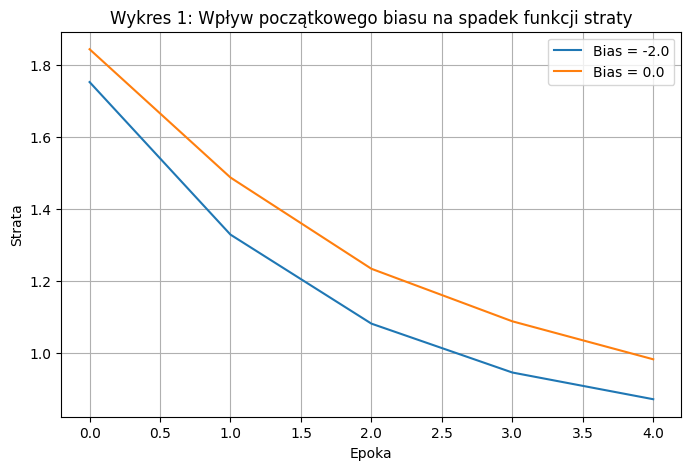

In [24]:
print("---  Trening: HighwayNet (bias = -2.0) ---")
net_negative_bias = DeepNet(net_type='highway', negative_bias=-2.0)
losses_negative_bias = train_experiment(net_negative_bias, epochs=5)

print("\n---  Trening: HighwayNet (bias = 0.0) ---")
net_zero_bias = DeepNet(net_type='highway', negative_bias=0.0)
losses_zero_bias = train_experiment(net_zero_bias, epochs=5)

plt.figure(figsize=(8,5))
plt.plot(losses_negative_bias, label="Bias = -2.0")
plt.plot(losses_zero_bias, label="Bias = 0.0")
plt.title("Wykres 1: Wpływ początkowego biasu na spadek funkcji straty")
plt.xlabel("Epoka")
plt.ylabel("Strata")
plt.legend()
plt.grid(True)
plt.show()

## Eksperyment 2 - Wpływ głębokości (Plain vs Highway)

Autorzy zauważyli, że zwykłe sieci stają się coraz trudniejsze do trenowania przy zwiększającej się głębokości, a Highway Networks można bez problemu optymalizować. Poniżej zreprodukowano ten wniosek, naśladując krzywe konwergencji z wykresu 1.

--- Trening: PlainNet 20 warstw  ---
Epoka 1/10, strata: 1.8466, dokładność: 30.35%
Epoka 2/10, strata: 1.6521, dokładność: 38.80%
Epoka 3/10, strata: 1.4919, dokładność: 40.69%
Epoka 4/10, strata: 1.3352, dokładność: 49.39%
Epoka 5/10, strata: 1.2081, dokładność: 52.17%
Epoka 6/10, strata: 1.1346, dokładność: 49.66%
Epoka 7/10, strata: 1.0779, dokładność: 54.82%
Epoka 8/10, strata: 1.0248, dokładność: 50.22%
Epoka 9/10, strata: 0.9788, dokładność: 58.63%
Epoka 10/10, strata: 0.9570, dokładność: 62.17%

---  Trening: HighwayNet 20 warstw ---
Epoka 1/10, strata: 1.7685, dokładność: 30.24%
Epoka 2/10, strata: 1.3452, dokładność: 54.73%
Epoka 3/10, strata: 1.1159, dokładność: 59.62%
Epoka 4/10, strata: 0.9851, dokładność: 62.41%
Epoka 5/10, strata: 0.8944, dokładność: 57.54%
Epoka 6/10, strata: 0.8185, dokładność: 59.10%
Epoka 7/10, strata: 0.7698, dokładność: 47.13%
Epoka 8/10, strata: 0.7238, dokładność: 67.53%
Epoka 9/10, strata: 0.6821, dokładność: 64.58%
Epoka 10/10, strata: 0.6567, 

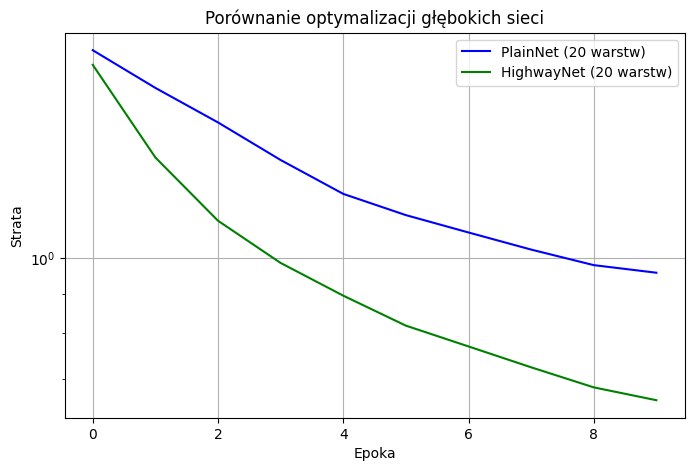

In [25]:
print("--- Trening: PlainNet 20 warstw  ---")
net_plain_20 = DeepNet(num_layers=20, net_type='plain')
loss_plain = train_experiment(net_plain_20, epochs=10)

print("\n---  Trening: HighwayNet 20 warstw ---")
net_highway_20 = DeepNet(num_layers=20, net_type='highway')
loss_highway = train_experiment(net_highway_20, epochs=10)

plt.figure(figsize=(8,5))
plt.plot(loss_plain, label="PlainNet (20 warstw)", color='blue')
plt.plot(loss_highway, label="HighwayNet (20 warstw)", color='green')
plt.title("Porównanie optymalizacji głębokich sieci")
plt.xlabel("Epoka")
plt.ylabel("Strata")
plt.yscale('log')
plt.legend()
plt.grid(True)
plt.show()

## Eksperyment 3 - Wizualizacja "Autostrad Informacyjnych"

Na koniec dokonano inspekcji wewnętrznego zachowania sieci wyuczonej w poprzednim kroku. Artykuł wskazuje, że wyjścia H(x) pozostają niemal stałe przez wiele warstw, a bramki transformacji aktywują się rzadko i są wysoce selektywne. Świadczy to o tym, że mechanizm jest wykorzystywany do routingu informacji, a nie tylko ułatwiania propagacji wstecznej.

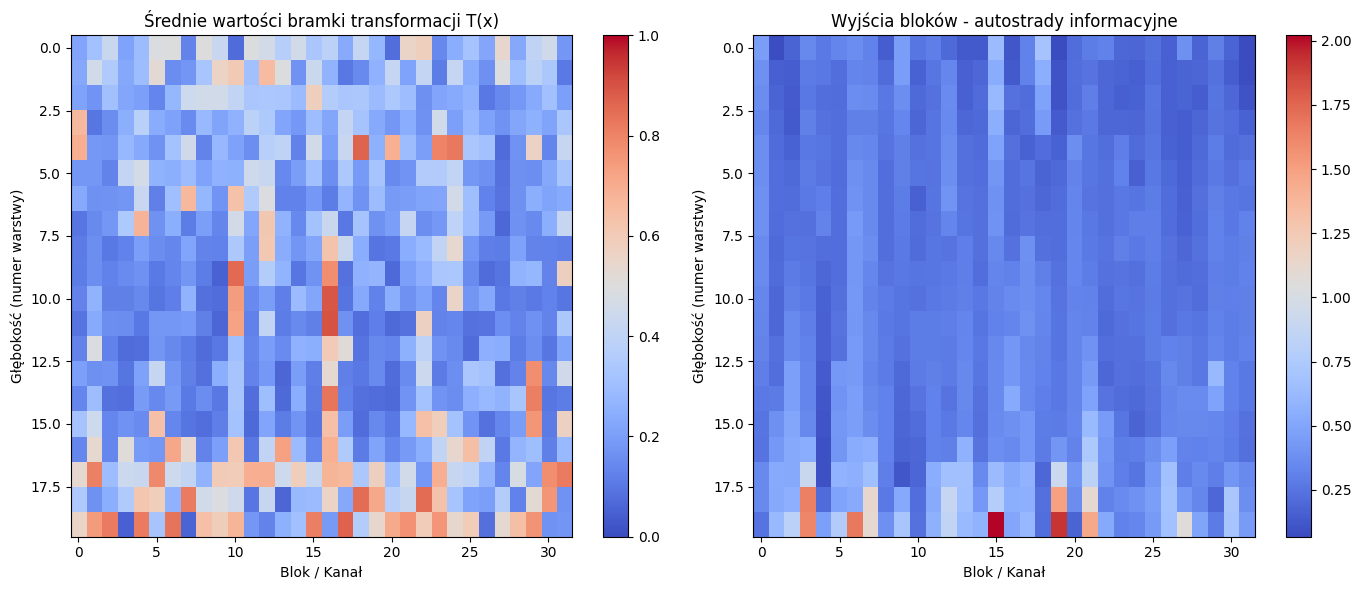

In [26]:
net_highway_20.eval()

dataiter = iter(test_loader)
images, labels = next(dataiter)
single_img = images[0].unsqueeze(0).to(device)

with torch.no_grad():
  _, gate_activations, block_outputs = net_highway_20(single_img, return_gates=True)

mean_gates = np.array([torch.mean(t[0], dim=(1,2)).cpu().numpy() for t in gate_activations])
mean_outputs = np.array([torch.mean(b[0], dim=(1,2)).cpu().numpy() for b in block_outputs])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
im1 = ax1.imshow(mean_gates, aspect='auto', cmap='coolwarm', vmin=0, vmax=1)
ax1.set_title("Średnie wartości bramki transformacji T(x)")
ax1.set_xlabel("Blok / Kanał")
ax1.set_ylabel("Głębokość (numer warstwy)")
fig.colorbar(im1, ax=ax1)

im2 = ax2.imshow(mean_outputs, aspect='auto', cmap='coolwarm')
ax2.set_title("Wyjścia bloków - autostrady informacyjne")
ax2.set_xlabel("Blok / Kanał")
ax2.set_ylabel("Głębokość (numer warstwy)")
fig.colorbar(im2, ax=ax2)

plt.tight_layout()
plt.show()



## Wnioski z wizualizacji i podsumowanie projektu



Wygenerowane mapy cieplne dostarczają unikalnych, empirycznych dowodów na to, jak wyuczona sieć inteligentnie steruje przepływem informacji za pomocą mechanizmu Highway Networks.

1. **Autostrady informacyjne jako pamięć długoterminowa:** Na prawym wykresie wyjść z bloków można zaobserwować, że dla konkretnych kanałów reprezentacja danych pozostaje niemal stała przez większość głębokości sieci. Bramki transformacji pozostają w tym czasie w dużej mierze nieaktywnem co oznacza, że sieć celowo decyduje się na domyślne przepuszczanie sygnału. Kluczowe cechy obrazu są bezpiecznie przetrzymywane i transportowane w głąb architektury bez zniekształceń wynikających z wielokrotnego mnożenia macierzy.

2. **Dynamiczne i selektywne przetwarzanie:** Tuż przed ostateczną warstwą klasyfikującą te same, nietknięte kanały gwałtownie zmieniają swój stan, poddając sygnał modyfikacji. Oznacza to, że sieć otwiera bramki transformacji dla przetrzymywanych cehc dopiero na samym końcu, poddając je silnej nieliniowej transformacji dokładnie w momencie, gdy są one niezbędne klasyfikatorowi do podjęcia ostatecznej decyzji.

**Podsumowanie:** Projekt udowadnia, że mechanizm bramek to potężne narzędzie do aktywnego routingu informacji. Wyuczony model dla zbioru CIFAR-10 wykształcił autonomiczną strategię przetrzymywania użytecznych cech w niezmienionej formie przez środek sieci, decydując się na ich ostateczne przetworzenie dopiero przed końcową warstwą decyzyjną.